# Practical: PCA Algorithm for Dimensionality Reduction

**Aim:**  
To use PCA Algorithm for dimensionality reduction. You have a dataset that includes measurements for different variables on wine (alcohol, ash, magnesium, and so on). Apply PCA algorithm & transform this data so that most variations in the measurements of the variables are captured by a small number of principal components so that it is easier to distinguish between wine classes by inspecting these principal components.

**Dataset Source:** `https://media.geeksforgeeks.org/wp-content/uploads/Wine.csv`

**Objectives:**  
1. Load the Wine dataset from the URL containing chemical attributes (Alcohol, Malic_Acid, Ash, Magnesium, etc.).
2. Standardize dataset features using `StandardScaler` (zero mean, unit variance).
3. Plot the Cumulative Explained Variance curve across all 13 principal components to observe variance distribution.
4. Apply Principal Component Analysis (PCA) to reduce 13 dimensions to 2 principal components.
5. Calculate and display the explained variance ratio of each principal component.
6. Visualize the transformed data in a 2D scatter plot to distinguish the wine segments.

In [1]:
# Cell 1 - Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
# Cell 2 - Load Dataset from URL
url = 'https://media.geeksforgeeks.org/wp-content/uploads/Wine.csv'
dataset = pd.read_csv(url)

# Display basic dataset details
print(f"Dataset Shape: {dataset.shape[0]} samples, {dataset.shape[1]} columns")
print("Wine Segments:", np.unique(dataset['Customer_Segment']))
print("\nFirst 5 rows of dataset:")
display(dataset.head()) if 'display' in globals() else print(dataset.head())

# Separate features (X) and target label (y)
X = dataset.iloc[:, 0:13].values
y = dataset['Customer_Segment'].values

Dataset Shape: 178 samples, 14 columns
Wine Segments: [1 2 3]

First 5 rows of dataset:
   Alcohol  Malic_Acid   Ash  Ash_Alcanity  Magnesium  Total_Phenols  \
0    14.23        1.71  2.43          15.6        127           2.80   
1    13.20        1.78  2.14          11.2        100           2.65   
2    13.16        2.36  2.67          18.6        101           2.80   
3    14.37        1.95  2.50          16.8        113           3.85   
4    13.24        2.59  2.87          21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   O

In [3]:
# Cell 3 - Feature Scaling (Standardization)
# PCA is sensitive to variance; features must be scaled to mean=0 and std=1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original Feature Mean (Alcohol):", round(np.mean(X[:, 0]), 2))
print("Scaled Feature Mean (Alcohol):", round(np.mean(X_scaled[:, 0]), 2))
print("Scaled Feature Std Dev (Alcohol):", round(np.std(X_scaled[:, 0]), 2))

Original Feature Mean (Alcohol): 13.0
Scaled Feature Mean (Alcohol): -0.0
Scaled Feature Std Dev (Alcohol): 1.0


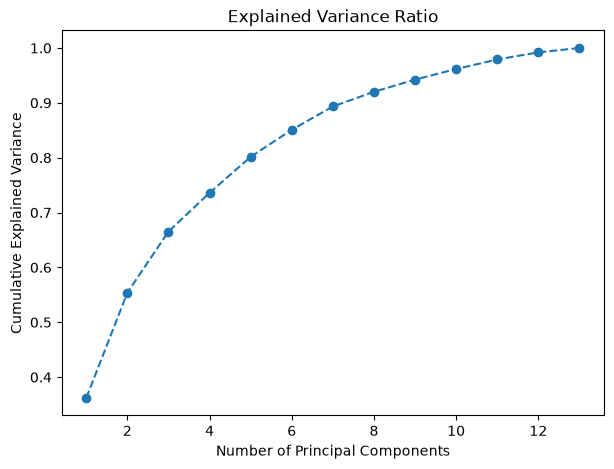

In [4]:
# Cell 4 - Cumulative Explained Variance Plot
# Fit PCA on all components to evaluate cumulative variance
pca_full = PCA().fit(X_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Plot Cumulative Explained Variance
plt.figure(figsize=(7, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.title("Explained Variance Ratio")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.show()

In [5]:
# Cell 5 - Apply PCA Algorithm (Reduce to 2 Principal Components)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create DataFrame for transformed data
df_pca = pd.DataFrame(data=X_pca, columns=['Principal Component 1', 'Principal Component 2'])
df_pca['Customer_Segment'] = y

# Check explained variance ratio
var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
total_var = np.sum(pca.explained_variance_ratio_) * 100

print(f"Transformed Shape: {X_pca.shape}")
print(f"Variance explained by PC1: {var_pc1:.2f}%")
print(f"Variance explained by PC2: {var_pc2:.2f}%")
print(f"Total Variance captured by 2 PCs: {total_var:.2f}%")

Transformed Shape: (178, 2)
Variance explained by PC1: 36.20%
Variance explained by PC2: 19.21%
Total Variance captured by 2 PCs: 55.41%


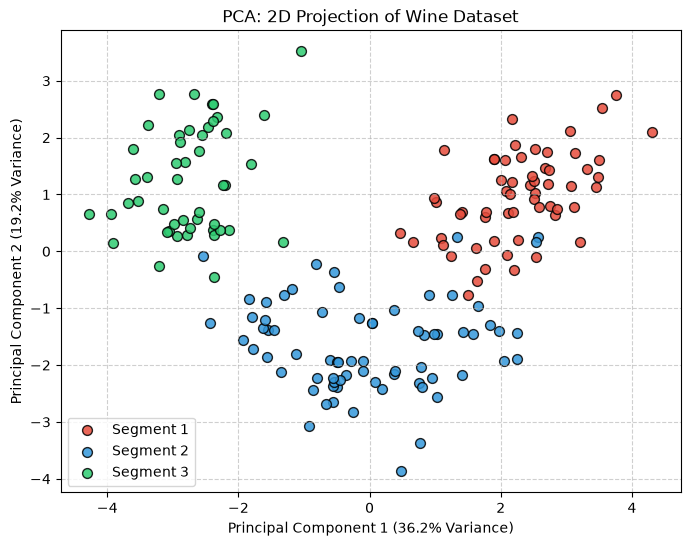

In [6]:
# Cell 6 - Visualize Transformed Data (2D Scatter Plot)
plt.figure(figsize=(8, 6))
colors = ['#e74c3c', '#3498db', '#2ecc71']
labels = ['Segment 1', 'Segment 2', 'Segment 3']

for i, segment in enumerate(np.unique(y)):
    plt.scatter(
        X_pca[y == segment, 0],
        X_pca[y == segment, 1],
        c=colors[i],
        label=labels[i],
        edgecolors='k',
        s=50,
        alpha=0.85
    )

plt.xlabel(f"Principal Component 1 ({var_pc1:.1f}% Variance)")
plt.ylabel(f"Principal Component 2 ({var_pc2:.1f}% Variance)")
plt.title("PCA: 2D Projection of Wine Dataset")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()